# Reducción de dimensionalidad — Análisis de Componentes Principales (PCA)

In [10]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns
import sys
import os
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


ruta_raiz = os.path.abspath('..')
if ruta_raiz not in sys.path:
    sys.path.append(ruta_raiz)

from config.rutas import RUTA_DATOS_CRUDOS
from src.cleaning.limpiado import casteo_datos
from src.cleaning.limpiado import limpieza_imputacion
from src.cleaning.pca import dimensionalidad


In [11]:
df_casteado= casteo_datos(RUTA_DATOS_CRUDOS)


/home/jose/Programming/AyMD/Practicas/practica_5/src/cleaning/limpiado.py:5: DtypeWarning: Columns (2,3,4,5,6,7) have mixed types. Specify dtype option on import or set low_memory=False.
  df_casteado= pd.read_csv(RUTA_DATOS_CRUDOS,sep=';')
/home/jose/Programming/AyMD/Practicas/practica_5/src/cleaning/limpiado.py:7: UserWarning: Parsing dates in %d/%m/%Y %H:%M:%S format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df_casteado['Date-time'] = pd.to_datetime(df_casteado['Date'].astype(str) + ' ' + df_casteado['Time'].astype(str))


In [12]:
df_limpio=limpieza_imputacion(df_casteado)

In [13]:
df_limpio = dimensionalidad(df_limpio)

In [14]:
df_limpio.describe().T

,count,mean,std,min,25%,50%,75%,max
Global_active_power,2075259.0,-2.812645e-16,1.0,-0.963569,-0.741268,-0.452467,0.415836,9.530169
Global_reactive_power,2075259.0,-2.019265e-16,1.0,-1.099893,-0.672920,-0.210366,0.625789,11.264526
Voltage,2075259.0,5.838475e-14,1.0,-5.445978,-0.569154,0.051645,0.629205,4.113092
Sub_metering_1,2075259.0,-5.669937e-17,1.0,-0.181412,-0.181412,-0.181412,-0.181412,14.207450
Sub_metering_2,2075259.0,-1.824241e-17,1.0,-0.222795,-0.222795,-0.222795,-0.049982,13.602222
Sub_metering_3,2075259.0,-3.722437e-17,1.0,-0.765505,-0.765505,-0.646682,1.254491,2.918017


Verificamos que nuestras variables estan estandarizadas antes de hacer PCA, ya que para realizarlo es necesario que nuestros datos esten estandarizados. 

Nuestra meta sera conservar el 80% de la varianza

In [15]:
pca = PCA(n_components=0.8)

datos_pca = pca.fit_transform(df_limpio)


nombres_columnas = [f'Componente_{i+1}' for i in range(datos_pca.shape[1])]
df_pca = pd.DataFrame(datos_pca, columns=nombres_columnas, index=df_limpio.index)

varianza_por_componente = pca.explained_variance_ratio_
varianza_total = sum(varianza_por_componente)



print(f"Número de componentes seleccionados: {pca.n_components_}")
print(f"Varianza explicada por cada componente: {varianza_por_componente}")

print(f"Varianza total explicada: {varianza_total * 100:.2f}%")



Número de componentes seleccionados: 4
Varianza explicada por cada componente: [0.38529209 0.16467295 0.15536236 0.14117004]
Varianza total explicada: 84.65%


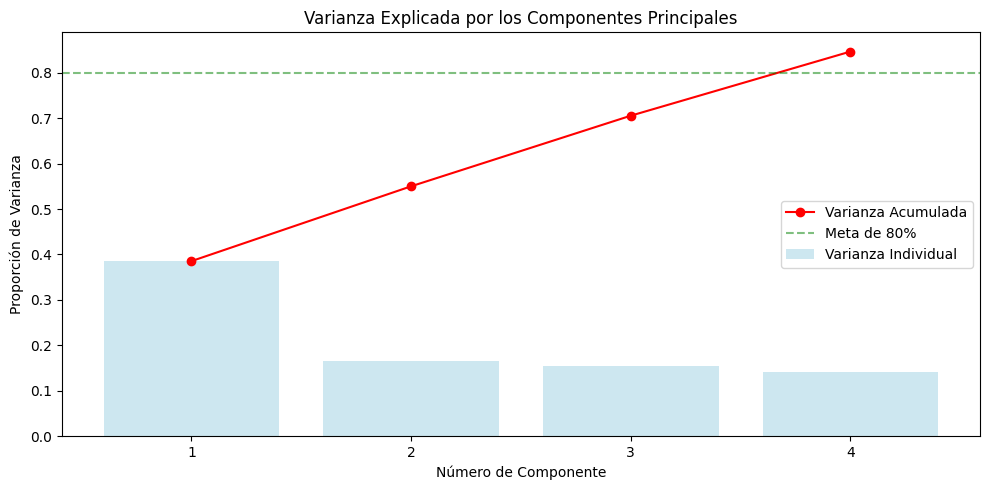

In [16]:
plt.figure(figsize=(10, 5))
varianza_acumulada = np.cumsum(varianza_por_componente)
componentes = range(1, len(varianza_por_componente) + 1)
plt.bar(componentes, varianza_por_componente, alpha=0.6, color='lightblue', label='Varianza Individual')
plt.plot(componentes, varianza_acumulada, marker='o', color='r', label='Varianza Acumulada')
plt.title('Varianza Explicada por los Componentes Principales')
plt.xlabel('Número de Componente')
plt.ylabel('Proporción de Varianza')
plt.xticks(componentes)
plt.axhline(y=0.8, color='green', linestyle='--', alpha=0.5, label='Meta de 80%') 
plt.legend()
plt.tight_layout()
plt.show()

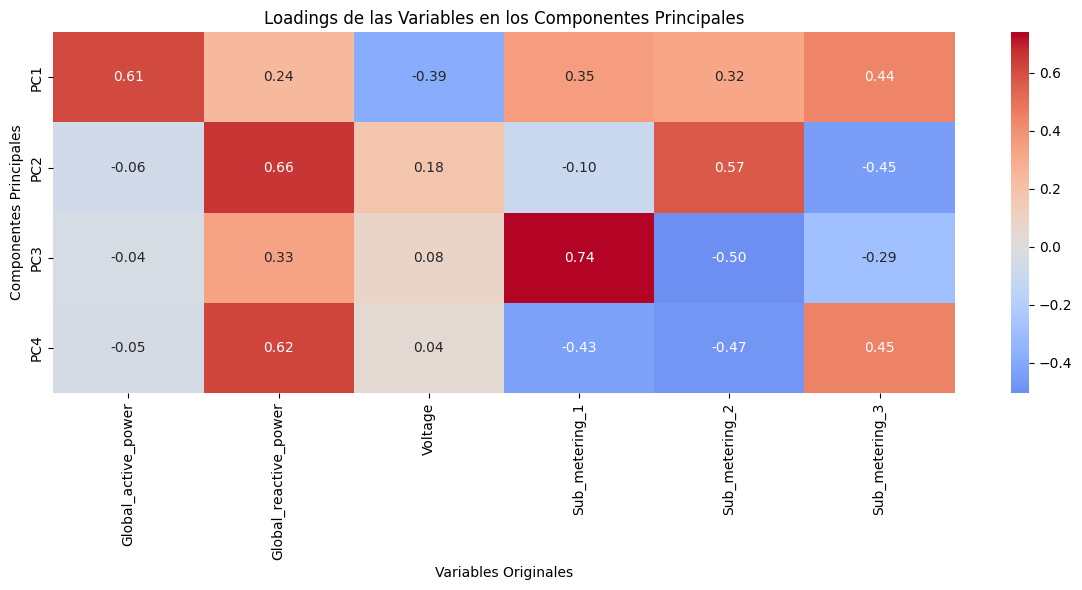

In [17]:


pesos = pca.components_


columnas_originales = df_limpio.columns 
df_pesos = pd.DataFrame(
    pesos, 
    columns=columnas_originales, 
    index=['PC1', 'PC2', 'PC3', 'PC4']
)


plt.figure(figsize=(12, 6))
sns.heatmap(df_pesos, cmap='coolwarm', annot=True, fmt=".2f", center=0)
plt.title('Loadings de las Variables en los Componentes Principales')
plt.xlabel('Variables Originales')
plt.ylabel('Componentes Principales')
plt.tight_layout()
plt.show()

## Interpretación de los Loadings


1. **Componente 1 (PC1 - 38.6% de varianza): Nivel General de Consumo Activo**  
   Presenta pesos positivos elevados en `Global_active_power` (0.61) y en los tres submedidores (`Sub_metering_3`: 0.44, `Sub_metering_1`: 0.36, `Sub_metering_2`: 0.32), acompañados de un peso negativo en `Voltage` (-0.39). Este componente captura el consumo total del hogar: cuando se encienden varios electrodomésticos a la vez, el consumo activo sube y el voltaje de la red tiende a disminuir ligeramente.

2. **Componente 2 (PC2 - 16.5% de varianza): Potencia Reactiva vs Climatización**  
   Tiene una carga positiva en `Global_reactive_power` (0.69) y `Sub_metering_2` (0.49, cuarto de lavado), a diferencia de la forma negativa con `Sub_metering_3` (-0.50, calentador de agua y aire acondicionado). Separa el uso de cargas inductivas/reactivas frente a grandes cargas térmicas.

3. **Componente 3 (PC3 - 15.6% de varianza): Cocina vs Lavandería**  
   Está dominado por `Sub_metering_1` (0.73, cocina: microondas, lavavajillas) contra `Sub_metering_2` (-0.60, lavandería: lavadora/secadora). Discrimina momentos de actividad culinaria frente a momentos de lavado de ropa.

4. **Componente 4 (PC4 - 13.9% de varianza): Reactiva Combinada con Climatización**  
   Presenta cargas positivas en `Global_reactive_power` (0.63) y `Sub_metering_3` (0.43), con cargas negativas en los demás submedidores.


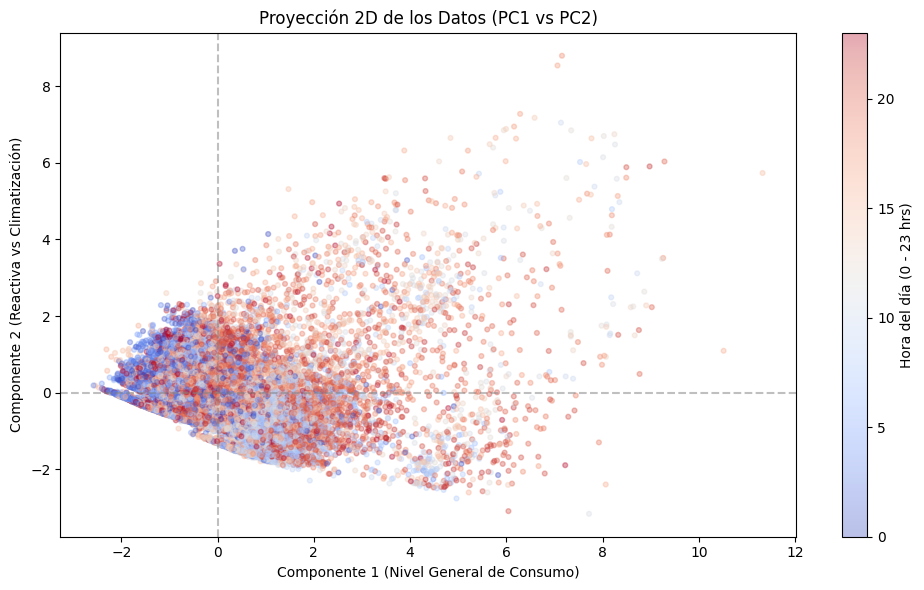

In [18]:
# Proyección en 2D: PC1 vs PC2
# Usamos una muestra representativa de 25,000 registros
np.random.seed(42)
indices_muestra = np.random.choice(len(df_pca), size=25000, replace=False)
df_pca_muestra = df_pca.iloc[indices_muestra].copy()
df_pca_muestra['Hora'] = df_pca_muestra.index.hour

plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    df_pca_muestra['Componente_1'], 
    df_pca_muestra['Componente_2'], 
    c=df_pca_muestra['Hora'], 
    cmap='coolwarm', 
    alpha=0.35, 
    s=12
)
cbar = plt.colorbar(scatter)
cbar.set_label('Hora del día (0 - 23 hrs)')
plt.title('Proyección 2D de los Datos (PC1 vs PC2)')
plt.xlabel('Componente 1 (Nivel General de Consumo)')
plt.ylabel('Componente 2 (Reactiva vs Climatización)')
plt.axvline(x=0, color='gray', linestyle='--', alpha=0.5)
plt.axhline(y=0, color='gray', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


## Análisis de Patrones en la Proyección 2D

Al proyectar los datos sobre el plano definido por los dos primeros componentes principales coloreados por la hora del día, se observan patrones de comportamiento doméstico:

- **Agrupamiento en reposo (PC1 < 0):** En la región izquierda se concentra una masa densa de puntos azules oscuros (horas de la madrugada, 00:00 a 06:00 hrs). Esto representa el consumo base mínimo del hogar cuando la mayoría de los habitantes duermen y solo operan aparatos esenciales en reposo (refrigerador, electrónica en espera).
- **Dispersión por actividad diurna y vespertina (PC1 > 0):** Conforme el Componente 1 toma valores positivos hacia la derecha, los puntos se dispersan y corresponden predominantemente a horas de la tarde y noche (tonos rojos y anaranjados, 18:00 a 22:00 hrs), coincidiendo con los picos diarios donde operan múltiples electrodomésticos.


In [19]:
# Incorporar los componentes retenidos al dataset preparado
df_preparado = df_limpio.join(df_pca)
print(f'Dimensiones del dataset final preparado: {df_preparado.shape}')
df_preparado.head()


Dimensiones del dataset final preparado: (2075259, 10)


,Global_active_power,Global_reactive_power,Voltage,Sub_metering_1,Sub_metering_2,Sub_metering_3,Componente_1,Componente_2,Componente_3,Componente_4
Date-time,,,,,,,,,,
2006-12-16 17:24:00,2.969445,2.618328,-1.850903,-0.181412,-0.049982,1.254491,3.634729,0.638138,0.131053,2.078053
2006-12-16 17:25:00,4.056249,2.778443,-2.224618,-0.181412,-0.049982,1.135667,4.429708,0.661796,0.148689,2.059466
2006-12-16 17:26:00,4.069549,3.329949,-2.329629,-0.181412,0.122830,1.254491,4.719258,1.050120,0.199617,2.369481
2006-12-16 17:27:00,4.082849,3.365531,-2.190644,-0.181412,-0.049982,1.254491,4.627391,0.999668,0.309432,2.478709
2006-12-16 17:28:00,2.446943,3.596807,-1.591465,-0.181412,-0.049982,1.254491,3.452532,1.361205,0.493006,2.723000


# Paso 6: Consolidación del dataset preparado

Se crea la versión final del dataset preparado (`consumo_preparado.parquet`), el cual reúne las variables limpias, con normalización Z-score ajustada sin fuga temporal, sin la columna redundante `Global_intensity` y con los 4 componentes principales incorporados.

*Nota:* Se utiliza el formato **Apache Parquet** por optimización de almacenamiento columnar y velocidad de lectura para el dashboard. Dejamos la linea de codigo comentada por si se requiere regresar al formato csv, lo hicimos así para que pueda subirse a github sin el problema del limite de tamaño


In [20]:
import os

# Ruta de salida para el dataset preparado final
os.makedirs('../data/data-processed', exist_ok=True)
ruta_preparado = '../data/data-processed/consumo_preparado.parquet'
df_preparado.to_parquet(ruta_preparado)

# Si se desea exportar a CSV plano en la máquina local:
# df_preparado.to_csv('../data/data-processed/consumo_preparado.csv')

print(f'Dataset preparado guardado exitosamente en: {ruta_preparado}')


Dataset preparado guardado exitosamente en: ../data/data-processed/consumo_preparado.parquet
